In [95]:
!pip install prophet openpyxl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [96]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [97]:
df = pd.read_excel("/content/drive/MyDrive/SEM 7/Coffee Shop Sales.xlsx")
df.head()

,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg


In [98]:
print("Ukuran dataset:", df.shape)
print("\nNama kolom:")
print(df.columns.tolist())

print("\nLima baris pertama:")
display(df.head())

print("\nInformasi data:")
df.info()

print("\nJumlah missing value:")
print(df.isnull().sum())

Ukuran dataset: (149116, 11)

Nama kolom:
['transaction_id', 'transaction_date', 'transaction_time', 'transaction_qty', 'store_id', 'store_location', 'product_id', 'unit_price', 'product_category', 'product_type', 'product_detail']

Lima baris pertama:


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
0,1,2023-01-01,07:06:11,2,5,Lower Manhattan,32,3.0,Coffee,Gourmet brewed coffee,Ethiopia Rg
1,2,2023-01-01,07:08:56,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg
2,3,2023-01-01,07:14:04,2,5,Lower Manhattan,59,4.5,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
3,4,2023-01-01,07:20:24,1,5,Lower Manhattan,22,2.0,Coffee,Drip coffee,Our Old Time Diner Blend Sm
4,5,2023-01-01,07:22:41,2,5,Lower Manhattan,57,3.1,Tea,Brewed Chai tea,Spicy Eye Opener Chai Lg



Informasi data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 149116 entries, 0 to 149115
Data columns (total 11 columns):
 #   Column            Non-Null Count   Dtype         
---  ------            --------------   -----         
 0   transaction_id    149116 non-null  int64         
 1   transaction_date  149116 non-null  datetime64[ns]
 2   transaction_time  149116 non-null  object        
 3   transaction_qty   149116 non-null  int64         
 4   store_id          149116 non-null  int64         
 5   store_location    149116 non-null  object        
 6   product_id        149116 non-null  int64         
 7   unit_price        149116 non-null  float64       
 8   product_category  149116 non-null  object        
 9   product_type      149116 non-null  object        
 10  product_detail    149116 non-null  object        
dtypes: datetime64[ns](1), float64(1), int64(4), object(5)
memory usage: 12.5+ MB

Jumlah missing value:
transaction_id      0
transaction_date    0
transact

Filter data

In [99]:
# Mengubah tanggal ke format datetime
df["transaction_date"] = pd.to_datetime(
    df["transaction_date"],
    errors="coerce"
)

# Mengubah kuantitas menjadi numerik
df["transaction_qty"] = pd.to_numeric(
    df["transaction_qty"],
    errors="coerce"
)

# Menghapus baris yang tanggal atau kuantitasnya tidak valid
df = df.dropna(
    subset=["transaction_date", "transaction_qty", "store_location"]
)

# Memastikan kuantitas tidak negatif
df = df[df["transaction_qty"] >= 0]

# Memilih satu lokasi
df_lokasi = df[
    df["store_location"] == "Hell's Kitchen"
].copy()

print("Jumlah baris setelah filter:", len(df_lokasi))
print("Tanggal awal:", df_lokasi["transaction_date"].min())
print("Tanggal akhir:", df_lokasi["transaction_date"].max())

display(df_lokasi.head())

Jumlah baris setelah filter: 50735
Tanggal awal: 2023-01-01 00:00:00
Tanggal akhir: 2023-06-30 00:00:00


,transaction_id,transaction_date,transaction_time,transaction_qty,store_id,store_location,product_id,unit_price,product_category,product_type,product_detail
17,18,2023-01-01,08:00:18,1,8,Hell's Kitchen,42,2.50,Tea,Brewed herbal tea,Lemon Grass Rg
18,19,2023-01-01,08:00:39,2,8,Hell's Kitchen,59,4.50,Drinking Chocolate,Hot chocolate,Dark chocolate Lg
19,20,2023-01-01,08:11:45,1,8,Hell's Kitchen,61,4.75,Drinking Chocolate,Hot chocolate,Sustainably Grown Organic Lg
20,21,2023-01-01,08:17:27,2,8,Hell's Kitchen,33,3.50,Coffee,Gourmet brewed coffee,Ethiopia Lg
23,24,2023-01-01,08:29:38,1,8,Hell's Kitchen,56,2.55,Tea,Brewed Chai tea,Spicy Eye Opener Chai Rg


Penjualan per hari

In [100]:
# Menjumlahkan kuantitas penjualan setiap hari
data_harian = (
    df_lokasi
    .groupby("transaction_date")["transaction_qty"]
    .sum()
    .reset_index()
)

# Menyesuaikan nama kolom untuk Prophet
data_harian = data_harian.rename(
    columns={
        "transaction_date": "ds",
        "transaction_qty": "y"
    }
)

# Membuat rentang tanggal harian yang lengkap
rentang_tanggal = pd.date_range(
    start=data_harian["ds"].min(),
    end=data_harian["ds"].max(),
    freq="D"
)

data_harian = (
    data_harian
    .set_index("ds")
    .reindex(rentang_tanggal, fill_value=0)
    .rename_axis("ds")
    .reset_index()
)

print("Jumlah data harian:", len(data_harian))
print("\nData harian:")
display(data_harian.head(10))

print("\nStatistik deskriptif:")
display(data_harian["y"].describe())

Jumlah data harian: 181

Data harian:


,ds,y
0,2023-01-01,270
1,2023-01-02,272
2,2023-01-03,295
3,2023-01-04,256
4,2023-01-05,235
5,2023-01-06,256
6,2023-01-07,323
7,2023-01-08,277
8,2023-01-09,272
9,2023-01-10,273



Statistik deskriptif:


,y
count,181.000000
mean,396.337017
std,129.535462
min,195.000000
25%,290.000000
50%,363.000000
75%,483.000000
max,769.000000


EDA

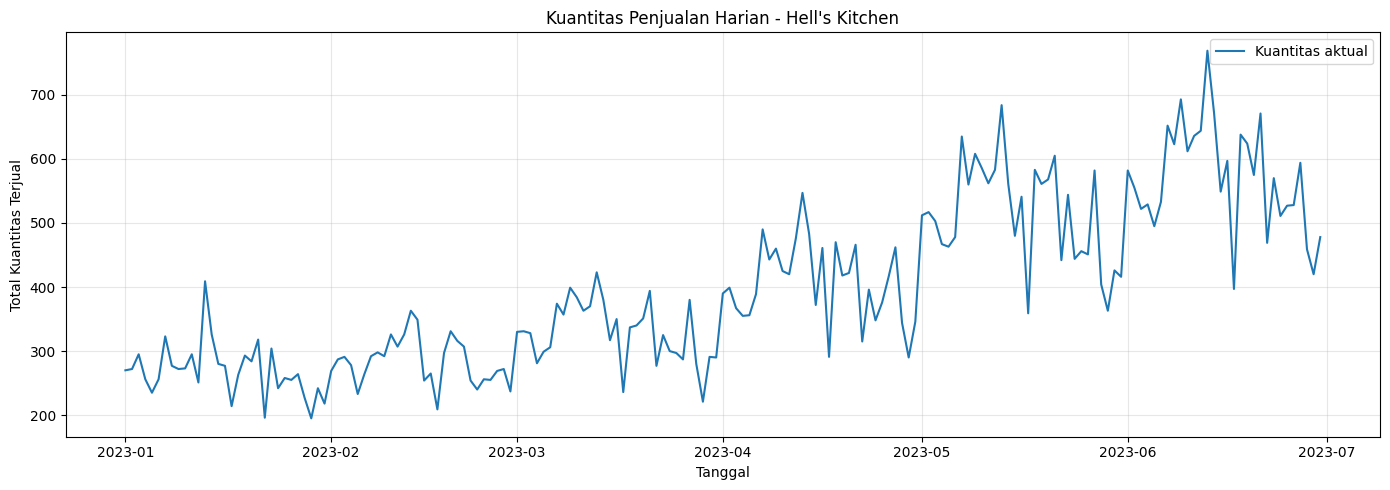

In [101]:
plt.figure(figsize=(14, 5))

plt.plot(
    data_harian["ds"],
    data_harian["y"],
    label="Kuantitas aktual"
)

plt.title("Kuantitas Penjualan Harian - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Total Kuantitas Terjual")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pola penjuala berdasarkan hari

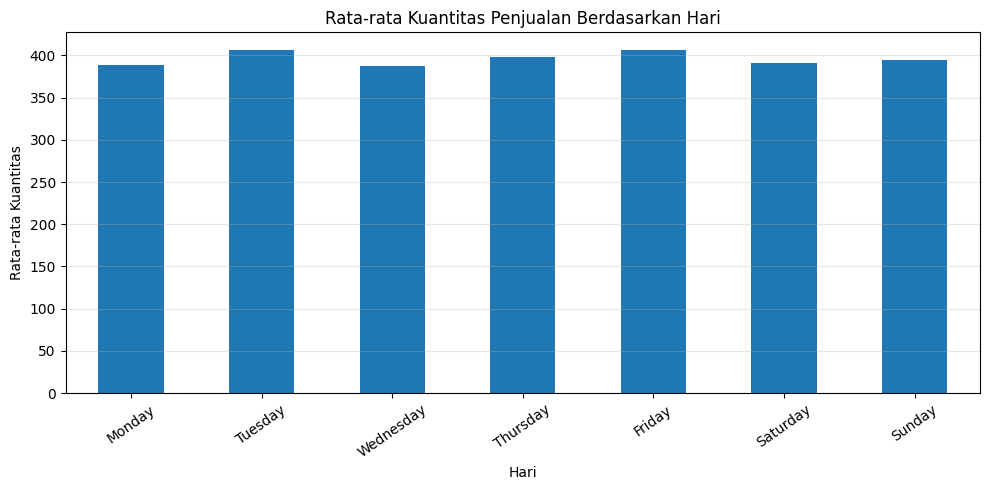

In [102]:
data_harian["nama_hari"] = (
    data_harian["ds"].dt.day_name()
)

urutan_hari = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

rata_hari = (
    data_harian
    .groupby("nama_hari")["y"]
    .mean()
    .reindex(urutan_hari)
)

plt.figure(figsize=(10, 5))
rata_hari.plot(kind="bar")

plt.title("Rata-rata Kuantitas Penjualan Berdasarkan Hari")
plt.xlabel("Hari")
plt.ylabel("Rata-rata Kuantitas")
plt.xticks(rotation=35)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Pemisahan data training dan testing

In [103]:
# Pastikan urutan tanggal sudah benar
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Pembagian berdasarkan waktu
split_index = int(len(data_harian) * 0.80)

train = data_harian.iloc[:split_index][["ds", "y"]].copy()
test = data_harian.iloc[split_index:][["ds", "y"]].copy()

print("Jumlah data training:", len(train))
print("Jumlah data testing:", len(test))

print("\nPeriode training:")
print(train["ds"].min(), "sampai", train["ds"].max())

print("\nPeriode testing:")
print(test["ds"].min(), "sampai", test["ds"].max())

Jumlah data training: 144
Jumlah data testing: 37

Periode training:
2023-01-01 00:00:00 sampai 2023-05-24 00:00:00

Periode testing:
2023-05-25 00:00:00 sampai 2023-06-30 00:00:00


Model Prophet

In [104]:
from prophet import Prophet

model_prophet = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_prophet.fit(train)

print("Model Prophet berhasil dilatih.")

Model Prophet berhasil dilatih.


Penjelasan konfigurasi:
- yearly_seasonality	False	Menonaktifkan pola musiman tahunan

- weekly_seasonality	True	Mengaktifkan pola musiman mingguan

- daily_seasonality	False	Menonaktifkan pola musiman harian

- seasonality_mode	"additive"	Menganggap efek musiman bersifat aditif

- interval_width	0.95	Interval prediksi 95%

- changepoint_prior_scale	Tidak diatur	Menggunakan nilai default Prophet

- seasonality_prior_scale	Tidak diatur	Menggunakan nilai default Prophet

Prediksi pada data testing

In [105]:
# Mengambil tanggal testing saja
tanggal_test = test[["ds"]].copy()

# Melakukan prediksi
pred_test = model_prophet.predict(tanggal_test)

# Menggabungkan aktual dan prediksi
hasil_test = test.merge(
    pred_test[["ds", "yhat", "yhat_lower", "yhat_upper"]],
    on="ds",
    how="left"
)

# Kuantitas tidak mungkin negatif.
# Nilai yhat_raw tetap disimpan untuk transparansi.
hasil_test["yhat_raw"] = hasil_test["yhat"]
hasil_test["yhat"] = hasil_test["yhat"].clip(lower=0)

display(hasil_test.head(10))

,ds,y,yhat,yhat_lower,yhat_upper,yhat_raw
0,2023-05-25,456,543.630321,423.390872,660.032066,543.630321
1,2023-05-26,451,543.404265,415.252584,657.534552,543.404265
2,2023-05-27,582,540.595157,420.524789,655.042559,540.595157
3,2023-05-28,404,548.543645,433.359846,670.774794,548.543645
4,2023-05-29,363,546.179838,433.727589,659.157399,546.179838
5,2023-05-30,426,557.560110,443.601706,680.043458,557.560110
6,2023-05-31,416,535.625965,415.776570,655.148575,535.625965
7,2023-06-01,582,564.308083,444.105469,692.717170,564.308083
8,2023-06-02,555,564.082028,445.821495,680.760262,564.082028
9,2023-06-03,522,561.272920,442.519476,679.662233,561.272920


Evaluasi model prophet

In [106]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

y_actual = hasil_test["y"].to_numpy()
y_pred = hasil_test["yhat"].to_numpy()

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_actual, y_pred)
)

# MAPE hanya dihitung untuk nilai aktual bukan nol
mask = y_actual != 0

if mask.any():
    mape = np.mean(
        np.abs(
            (y_actual[mask] - y_pred[mask])
            / y_actual[mask]
        )
    ) * 100
else:
    mape = np.nan

# SMAPE dengan perlindungan terhadap pembagi nol
denominator = np.abs(y_actual) + np.abs(y_pred)

smape_per_baris = np.divide(
    2 * np.abs(y_actual - y_pred),
    denominator,
    out=np.zeros_like(denominator, dtype=float),
    where=denominator != 0
)

smape = np.mean(smape_per_baris) * 100

evaluasi_prophet = pd.DataFrame({
    "Metrik": ["MAE", "RMSE", "MAPE (%)", "SMAPE (%)"],
    "Nilai": [mae, rmse, mape, smape]
})

display(evaluasi_prophet.round(4))

,Metrik,Nilai
0,MAE,87.2320
1,RMSE,104.5342
2,MAPE (%),17.6828
3,SMAPE (%),15.9248


Visualisasi aktual vs prediksi

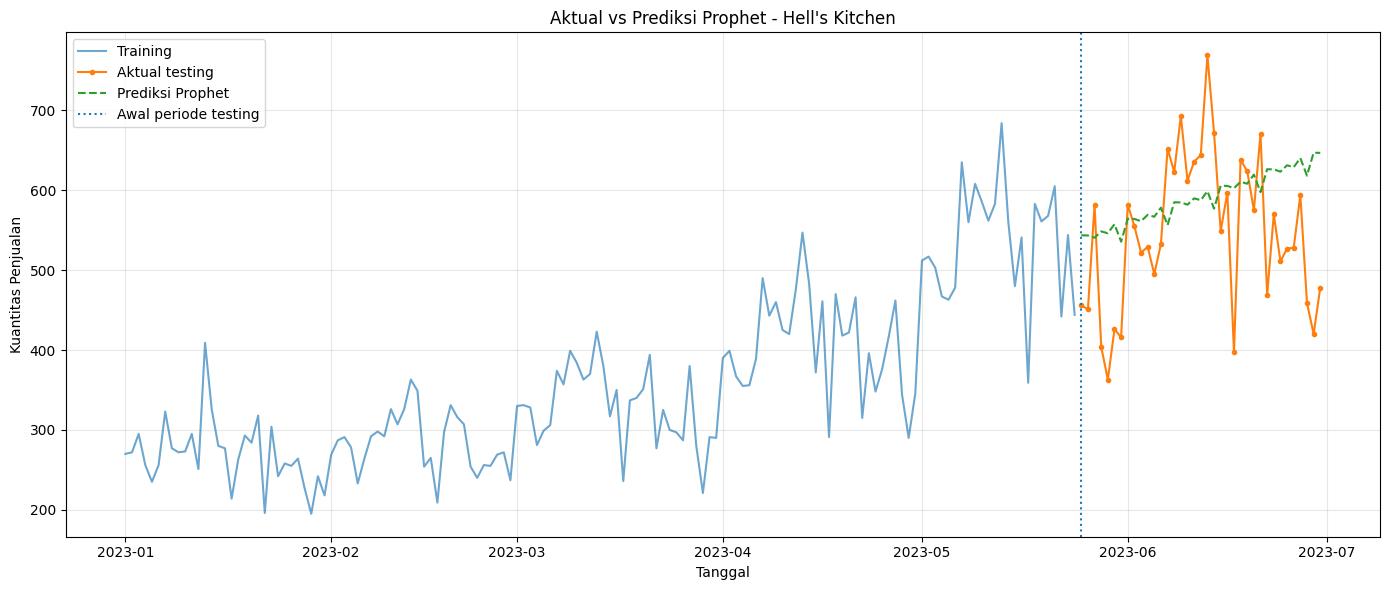

In [107]:
plt.figure(figsize=(14, 6))

plt.plot(
    train["ds"],
    train["y"],
    label="Training",
    alpha=0.65
)

plt.plot(
    hasil_test["ds"],
    hasil_test["y"],
    label="Aktual testing",
    marker="o",
    markersize=3
)

plt.plot(
    hasil_test["ds"],
    hasil_test["yhat"],
    label="Prediksi Prophet",
    linestyle="--"
)

plt.axvline(
    test["ds"].min(),
    linestyle=":",
    label="Awal periode testing"
)

plt.title("Aktual vs Prediksi Prophet - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Prediksi 1 hari berikutnya

In [108]:
# Model final dilatih dengan seluruh data
model_final = Prophet(
    yearly_seasonality=False,
    weekly_seasonality=True,
    daily_seasonality=False,
    seasonality_mode="additive",
    interval_width=0.95
)

model_final.fit(data_harian[["ds", "y"]])

# Membuat tanggal satu hari setelah data terakhir
future = model_final.make_future_dataframe(
    periods=1,
    freq="D",
    include_history=True
)

forecast = model_final.predict(future)

# Ambil tanggal setelah tanggal terakhir data aktual
tanggal_terakhir = data_harian["ds"].max()

hasil_1_hari = forecast[
    forecast["ds"] > tanggal_terakhir
][["ds", "yhat", "yhat_lower", "yhat_upper"]].copy()

# Penyesuaian untuk kuantitas yang tidak mungkin negatif
for kolom in ["yhat", "yhat_lower", "yhat_upper"]:
    hasil_1_hari[kolom] = hasil_1_hari[kolom].clip(lower=0)

# Pembulatan untuk tampilan kuantitas
hasil_1_hari["prediksi_kuantitas"] = (
    hasil_1_hari["yhat"].round().astype(int)
)

display(hasil_1_hari)

,ds,yhat,yhat_lower,yhat_upper,prediksi_kuantitas
181,2023-07-01,590.224253,449.822286,717.542095,590


Visualisasi prediksi 1 hari ke depan

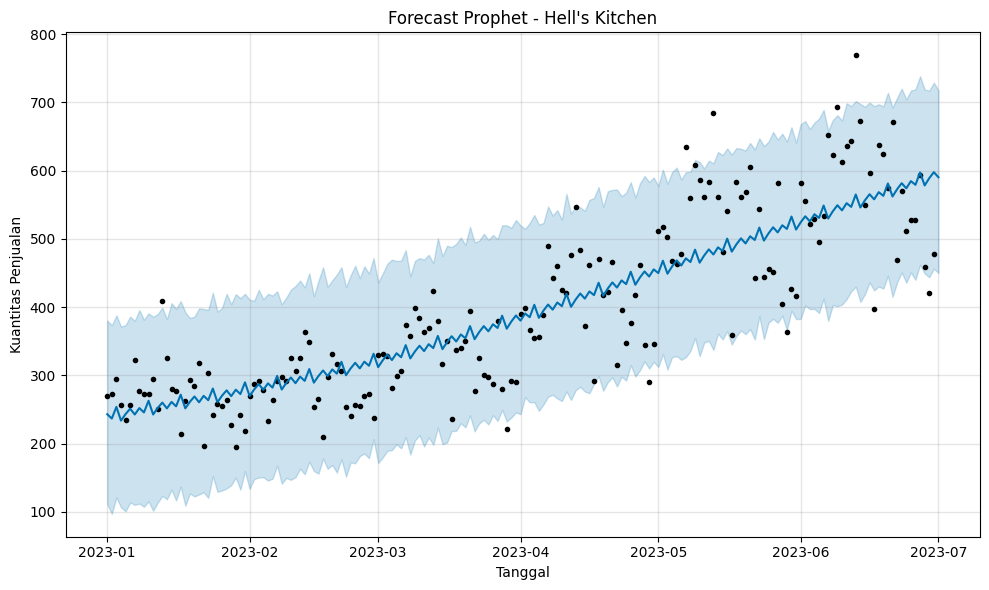

In [109]:
fig = model_final.plot(forecast)

plt.title("Forecast Prophet - Hell's Kitchen")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan")
plt.tight_layout()
plt.show()

Cari tanggal dengan kesalahan terbesar

In [110]:
hasil_analisis = hasil_test.copy()

hasil_analisis["error"] = (
    hasil_analisis["y"] - hasil_analisis["yhat"]
)

hasil_analisis["absolute_error"] = (
    hasil_analisis["error"].abs()
)

hasil_analisis = hasil_analisis.sort_values(
    "absolute_error",
    ascending=False
)

display(
    hasil_analisis[
        ["ds", "y", "yhat", "error", "absolute_error"]
    ].head(10)
)

,ds,y,yhat,error,absolute_error
35,2023-06-29,420,647.019135,-227.019135,227.019135
23,2023-06-17,397,602.628446,-205.628446,205.628446
4,2023-05-29,363,546.179838,-183.179838,183.179838
19,2023-06-13,769,598.915636,170.084364,170.084364
36,2023-06-30,478,646.793080,-168.793080,168.793080
34,2023-06-28,459,618.337017,-159.337017,159.337017
28,2023-06-22,469,626.341372,-157.341372,157.341372
3,2023-05-28,404,548.543645,-144.543645,144.543645
5,2023-05-30,426,557.560110,-131.560110,131.560110
6,2023-05-31,416,535.625965,-119.625965,119.625965


Grafik aktual vs prediksi

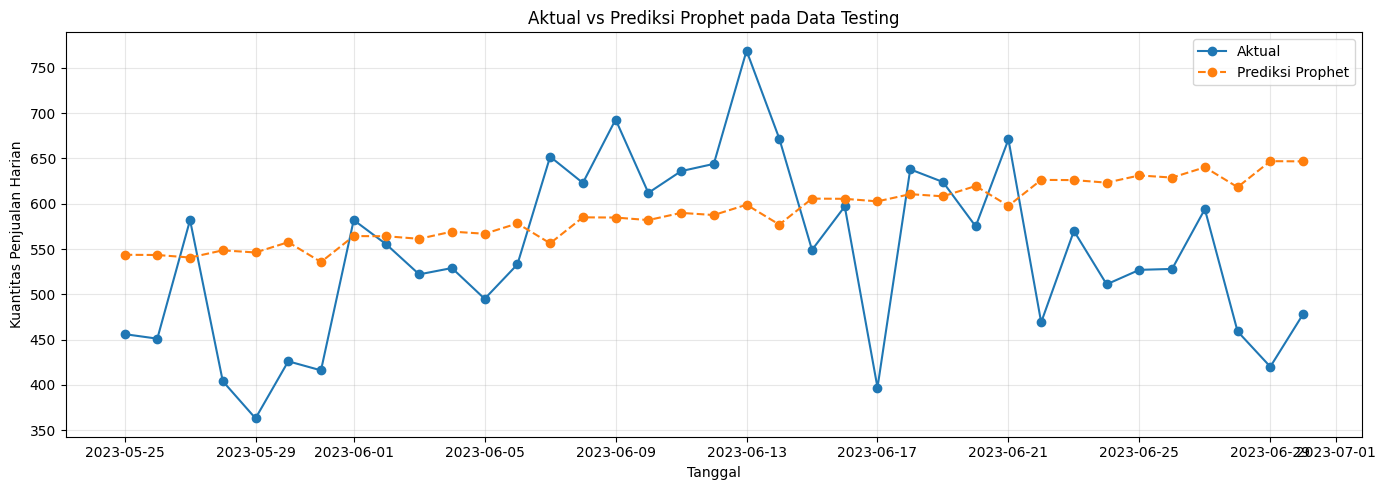

In [111]:
plt.figure(figsize=(14, 5))

plt.plot(
    hasil_test["ds"],
    hasil_test["y"],
    marker="o",
    label="Aktual"
)

plt.plot(
    hasil_test["ds"],
    hasil_test["yhat"],
    marker="o",
    linestyle="--",
    label="Prediksi Prophet"
)

plt.title("Aktual vs Prediksi Prophet pada Data Testing")
plt.xlabel("Tanggal")
plt.ylabel("Kuantitas Penjualan Harian")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

COBA PERBAIKAN

Pembagian data training dan validasi

In [112]:
import pandas as pd
import numpy as np
from prophet import Prophet

# Pastikan data urut berdasarkan tanggal
data_harian = data_harian[["ds", "y"]].copy()
data_harian["ds"] = pd.to_datetime(data_harian["ds"])
data_harian = data_harian.sort_values("ds").reset_index(drop=True)

# Sisihkan 20% data terakhir sebagai testing final
batas_test = int(len(data_harian) * 0.8)

data_train_val = data_harian.iloc[:batas_test].copy()
data_test_final = data_harian.iloc[batas_test:].copy()

# Bagi lagi data train_val menjadi training dan validasi
batas_val = int(len(data_train_val) * 0.8)

data_train = data_train_val.iloc[:batas_val].copy()
data_validasi = data_train_val.iloc[batas_val:].copy()

print("Jumlah data training :", len(data_train))
print("Jumlah data validasi :", len(data_validasi))
print("Jumlah data testing  :", len(data_test_final))

Jumlah data training : 115
Jumlah data validasi : 29
Jumlah data testing  : 37


Kombinasi konfigurasi

In [113]:
konfigurasi = [
    {
        "nama": "Baseline",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 10
    },
    {
        "nama": "CP rendah",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.01,
        "seasonality_prior_scale": 10
    },
    {
        "nama": "CP tinggi",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.1,
        "seasonality_prior_scale": 10
    },
    {
        "nama": "Seasonality rendah",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 1
    },
    {
        "nama": "Seasonality tinggi",
        "seasonality_mode": "additive",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 20
    },
    {
        "nama": "Multiplicative",
        "seasonality_mode": "multiplicative",
        "changepoint_prior_scale": 0.05,
        "seasonality_prior_scale": 10
    }
]

Latih dan evaluasi konfigurasi

In [114]:
def hitung_metrik(aktual, prediksi):
    aktual = np.asarray(aktual, dtype=float)
    prediksi = np.asarray(prediksi, dtype=float)

    # Penjualan tidak mungkin negatif
    prediksi = np.maximum(prediksi, 0)

    error = aktual - prediksi

    mae = np.mean(np.abs(error))
    rmse = np.sqrt(np.mean(error ** 2))

    # MAPE tidak dihitung pada aktual = 0
    mask = aktual != 0
    mape = (
        np.mean(np.abs(error[mask] / aktual[mask])) * 100
        if mask.any() else np.nan
    )

    # SMAPE; pasangan aktual dan prediksi yang sama-sama nol
    # diberi kontribusi error 0
    penyebut = np.abs(aktual) + np.abs(prediksi)
    smape_per_baris = np.divide(
        2 * np.abs(error),
        penyebut,
        out=np.zeros_like(penyebut, dtype=float),
        where=penyebut != 0
    )
    smape = np.mean(smape_per_baris) * 100

    return mae, rmse, mape, smape


hasil_konfigurasi = []

for cfg in konfigurasi:
    model = Prophet(
        yearly_seasonality=False,
        weekly_seasonality=True,
        daily_seasonality=False,
        seasonality_mode=cfg["seasonality_mode"],
        changepoint_prior_scale=cfg["changepoint_prior_scale"],
        seasonality_prior_scale=cfg["seasonality_prior_scale"]
    )

    model.fit(data_train)

    # Prediksi pada tanggal validasi
    future = data_validasi[["ds"]].copy()
    forecast = model.predict(future)

    aktual = data_validasi["y"].to_numpy()
    prediksi = np.maximum(forecast["yhat"].to_numpy(), 0)

    mae, rmse, mape, smape = hitung_metrik(
        aktual, prediksi
    )

    hasil_konfigurasi.append({
        "Konfigurasi": cfg["nama"],
        "Seasonality Mode": cfg["seasonality_mode"],
        "Changepoint Prior Scale": cfg["changepoint_prior_scale"],
        "Seasonality Prior Scale": cfg["seasonality_prior_scale"],
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape,
        "SMAPE (%)": smape
    })

tabel_hasil = pd.DataFrame(hasil_konfigurasi)

# Urutkan berdasarkan MAE terkecil
tabel_hasil = tabel_hasil.sort_values(
    "MAE", ascending=True
).reset_index(drop=True)

display(tabel_hasil.round(4))

,Konfigurasi,Seasonality Mode,Changepoint Prior Scale,Seasonality Prior Scale,MAE,RMSE,MAPE (%),SMAPE (%)
0,CP tinggi,additive,0.10,10,90.5270,105.0658,17.6857,18.6353
1,Multiplicative,multiplicative,0.05,10,101.5128,117.1808,19.3948,21.0996
2,Baseline,additive,0.05,10,101.5896,117.2178,19.4243,21.1068
3,Seasonality rendah,additive,0.05,1,101.6235,117.2527,19.4299,21.1144
4,Seasonality tinggi,additive,0.05,20,101.7574,117.3904,19.4517,21.1448
5,CP rendah,additive,0.01,10,106.7787,122.6365,20.2927,22.2936


Menentukan konfigurasi terbaik

In [115]:
terbaik = tabel_hasil.iloc[0]

print("Konfigurasi terbaik berdasarkan MAE:")
print("Nama       :", terbaik["Konfigurasi"])
print("MAE        :", round(terbaik["MAE"], 4))
print("RMSE       :", round(terbaik["RMSE"], 4))
print("MAPE (%)   :", round(terbaik["MAPE (%)"], 4))
print("SMAPE (%)  :", round(terbaik["SMAPE (%)"], 4))

Konfigurasi terbaik berdasarkan MAE:
Nama       : CP tinggi
MAE        : 90.527
RMSE       : 105.0658
MAPE (%)   : 17.6857
SMAPE (%)  : 18.6353
